In [1]:
from typing import List,Tuple
import os

import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

from constants import RANDOM_STATE, PLOTS_PATH, DATASET_HANDLE

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.competition_download(DATASET_HANDLE)
print("Path to competition files:", path)

Path to competition files: /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business


In [3]:
print("Competition data Directory files: ")
for file in os.listdir(path):
    print(file, "; path=", os.path.join(path,file))

Competition data Directory files: 
train.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/train.csv
submission_template.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/submission_template.csv
test.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/test.csv
data_description.txt ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/data_description.txt


In [4]:
df = pd.read_csv(os.path.join(path,"train.csv"))

df["health_points"] = 0
df.loc[df["Smoking"] == 0, "health_points"] += 1
df.loc[df["PhysicalActivity"] >= 2.5, "health_points"] += 1
df.loc[((df["AlcoholConsumption"]*8)/7 <= 15) & (df["Gender"] == 1), "health_points"] += 1 
df.loc[((df["AlcoholConsumption"]*8)/7 <= 30) & (df["Gender"] == 0), "health_points"] += 1
df.loc[df["DietQuality"] >= 8, "health_points"] += 1

df["BMI_cat"] = "Underweight"
df.loc[(df["BMI"] >= 18.5)&(df["BMI"] < 25), "BMI_cat"] = "Normal"
df.loc[(df["BMI"] >= 25)&(df["BMI"] < 30), "BMI_cat"] = "Overweight"
df.loc[df["BMI"] >= 30, "BMI_cat"] = "Obese"

df["cholesterol"] = df["CholesterolTotal"]/38.67
# Cholesterol is divided by 38.67 to convert from mm/dL to mmol/L https://heartcare.sydney/cholesterol-unit-conversion/

df["secondary_indicator"] = 2

# Favorable level of all major cardiovascular disease risk factors (blood pressure ≤120/≤80 mm Hg and no antihypertensive medication, serum cholesterol <5.18 mmol/L and no lipid-lowering medication, not smoking, bone mass index <25 kg/m2, no diabetes mellitus);
df.loc[(df["SystolicBP"] <= 120) & (df["DiastolicBP"] <= 80) & (df["cholesterol"] < 5.18) & (df["Smoking"] == 0) & (df["Diabetes"] == 0), "secondary_indicator"] = 3

# High-Risk: High systolic blood pressure/diastolic blood pressure (≥140/90) or using antihypertensive medication, serum total cholesterol ≥6.22 mmol/L or using lipid-lowering medication, smoking, bone mass index ≥30.0 kg/m2, diabetes mellitus.
df.loc[(df["SystolicBP"] >= 140) | (df["DiastolicBP"] >= 90) | (df["cholesterol"] >= 6.22) | (df["Diabetes"] == 1) | (df["Smoking"] == 1), "secondary_indicator"] = 1

#https://www.heart.org/en/health-topics/high-blood-pressure/understanding-blood-pressure-readings
#https://www.health.harvard.edu/heart-health/which-blood-pressure-number-matters-most
df.loc[(df["SystolicBP"] < 120) & (df["DiastolicBP"] < 80), "BP_CT"] = "Normal"
df.loc[(df["SystolicBP"] >= 120) & (df["SystolicBP"] <= 129) & (df["DiastolicBP"] < 80), "BP_CT"] = "Elevated"
df.loc[(df["SystolicBP"] >= 130) & (df["SystolicBP"] <= 139) & (df["DiastolicBP"] >= 80) & (df["DiastolicBP"] <= 89), "BP_CT"] = "Stage1"
df.loc[(df["SystolicBP"] >= 140) & (df["DiastolicBP"] >= 90), "BP_CT"] = "Stage2"
df.loc[(df["SystolicBP"] >= 180) | (df["DiastolicBP"] >= 120), "BP_CT"] = "Severe"

In [5]:
!cat "$path/data_description.txt"

About Dataset
This dataset contains extensive health information for 2,149 patients, each uniquely identified. The dataset includes demographic details, lifestyle factors, medical history, clinical measurements, cognitive and functional assessments, symptoms, and a diagnosis of Alzheimer's Disease. The data is ideal for researchers and data scientists looking to explore factors associated with Alzheimer's, develop predictive models, and conduct statistical analyses.

Table of Contents
Demographic Details
Lifestyle Factors
Medical History
Clinical Measurements
Cognitive and Functional Assessments
Symptoms
Diagnosis Information

Demographic Details
Age: The age of the patients ranges from 60 to 90 years.
Gender: Gender of the patients, where 0 represents Male and 1 represents Female.
Ethnicity: The ethnicity of the patients, coded as follows:
0: Caucasian
1: African American
2: Asian
3: Other

Lifestyle Factors
BMI: Body Mass Index of the patients, ranging from 15 to 40.
Smoking: Smoking

---

My idea is, I need to mine patterns some way. For the main model I need to understand better the lifestyle factors. For this one, I suppose that using trees and then assessing them 
would be a good idea.

For the second model, I need to verify other stuff, like symptoms, historic, cognitive/function assessments. I'm not sure for now, but I know that I need some things:

1. Balance data
2. Patterns for these variables

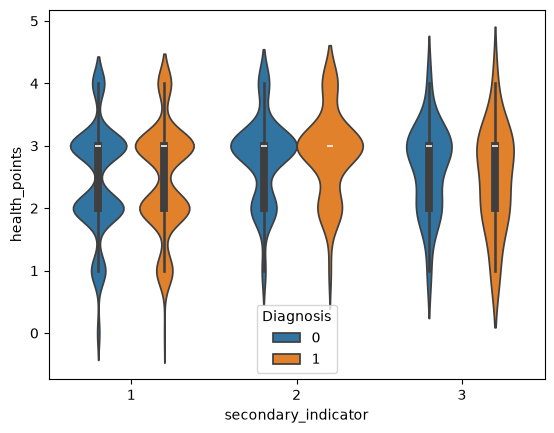

In [6]:
sns.violinplot(data=df,x="secondary_indicator", y="health_points", hue="Diagnosis")
plt.savefig(PLOTS_PATH("violin_secondary_points.png"),bbox_inches="tight")
plt.show()

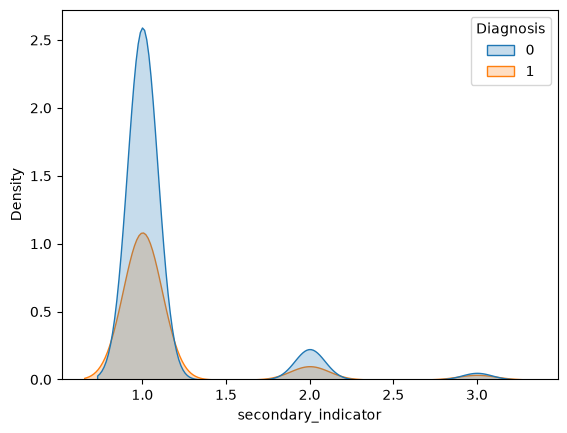

In [7]:
sns.kdeplot(data=df, x="secondary_indicator", hue="Diagnosis", fill=True)
plt.savefig(PLOTS_PATH("kde_secondary_points.png"),bbox_inches="tight")
plt.show()

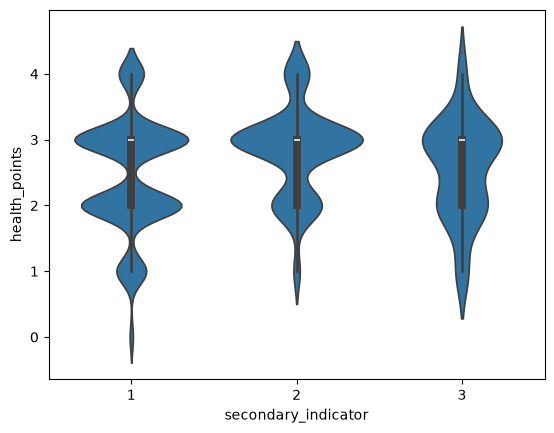

In [8]:
sns.violinplot(data=df,x="secondary_indicator", y="health_points")
plt.savefig(PLOTS_PATH("violin_secondary_points_raw.png"),bbox_inches="tight")
plt.show()

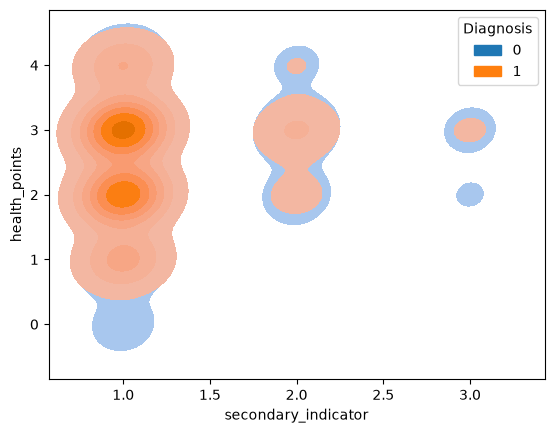

In [9]:
sns.kdeplot(data=df,x="secondary_indicator", y="health_points", hue="Diagnosis", fill=True)
plt.savefig(PLOTS_PATH("kde_blob_secondary_points.png"),bbox_inches="tight")
plt.show()

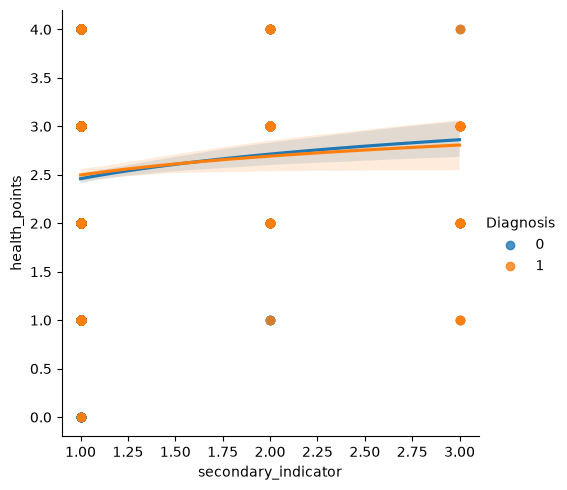

In [10]:
sns.lmplot(data=df, x="secondary_indicator", y="health_points", hue="Diagnosis", logx=True)
plt.savefig(PLOTS_PATH("reg_secondary_points.png"),bbox_inches="tight")
plt.show()

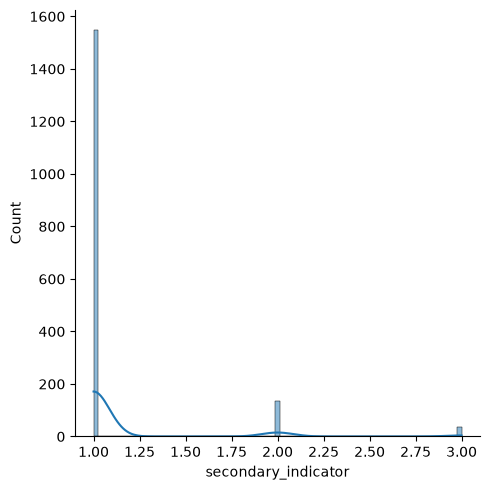

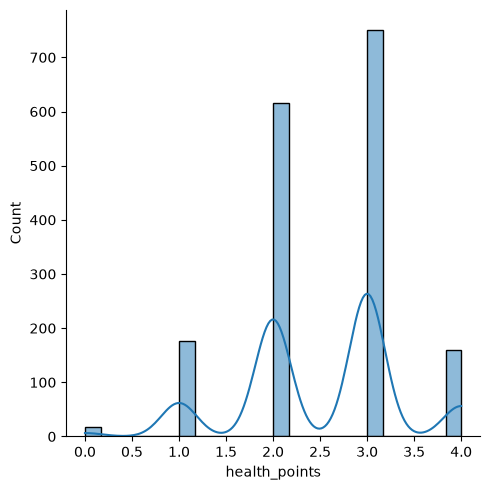

In [11]:
sns.displot(data=df, x="secondary_indicator", kde=True)
plt.savefig(PLOTS_PATH("dist_secondary.png"),bbox_inches="tight")
plt.show()

In [ ]:
sns.displot(data=df, x="health_points", kde=True)
plt.savefig(PLOTS_PATH("dist_points.png"),bbox_inches="tight")
plt.show()

In [12]:
indicator_1 = df.loc[df["secondary_indicator"] == 1]
indicator_diff_1 = df.loc[df["secondary_indicator"] != 1]

print("Total 1: ", len(indicator_1))
print("Total neq 1: ", len(indicator_diff_1))

df_s = pd.concat([indicator_diff_1, indicator_1.sample(n=len(indicator_diff_1))])
print("New temp df size: ", len(df_s))

assert len(df_s) == 2*len(indicator_diff_1)

Total 1:  1547
Total neq 1:  172
New temp df size:  344


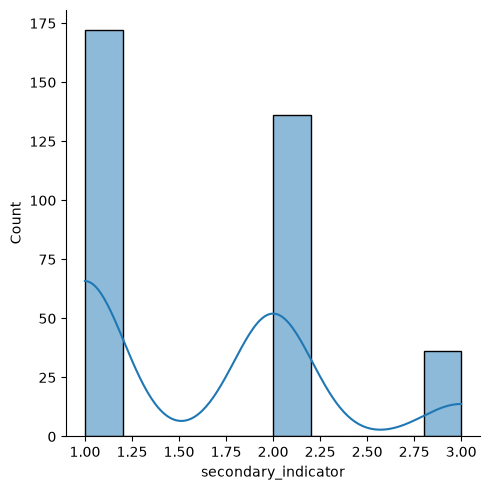

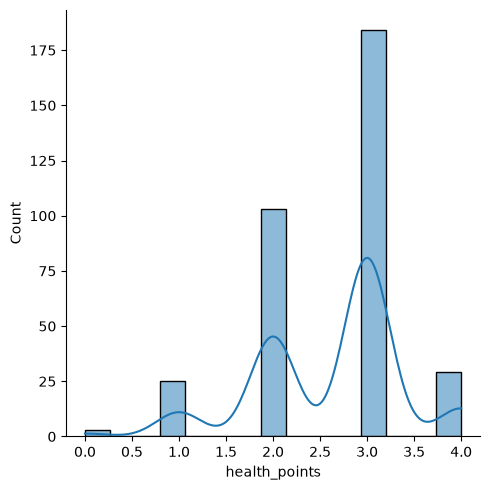

In [13]:
sns.displot(data=df_s, x="secondary_indicator", kde=True)
plt.savefig(PLOTS_PATH("dist_secondary_sample.png"),bbox_inches="tight")
plt.show()

In [ ]:
sns.displot(data=df_s, x="health_points", kde=True)
plt.savefig(PLOTS_PATH("dist_points_sample.png"),bbox_inches="tight")
plt.show()

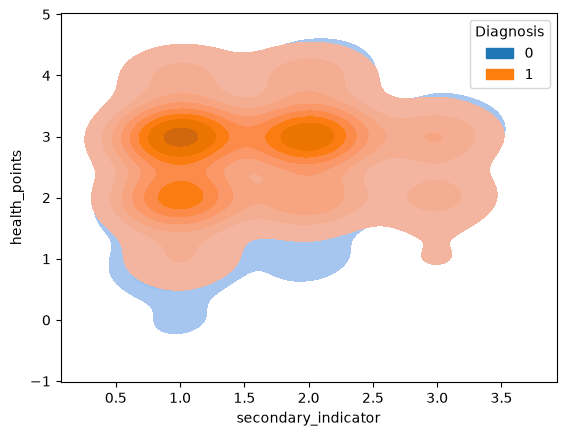

In [14]:
sns.kdeplot(data=df_s,x="secondary_indicator", y="health_points", hue="Diagnosis", fill=True)
plt.savefig(PLOTS_PATH("kde_blob_points_secondary_sample.png"),bbox_inches="tight")
plt.show()

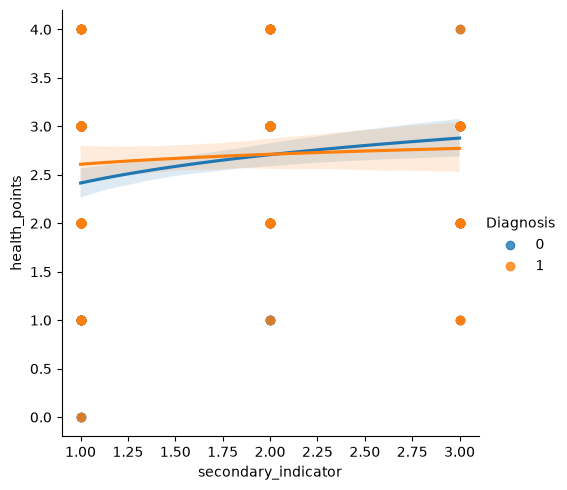

In [15]:
sns.lmplot(data=df_s, x="secondary_indicator", y="health_points", hue="Diagnosis", logx=True)
plt.savefig(PLOTS_PATH("reg_secondary_points_sampled.png"),bbox_inches="tight")
plt.show()

Ok, so we see that the correct indicator is pointing to a massive region that people actually has the disease, but using regression it's not that easy to see that stuff.

I suppose, that because we have some people with an specific amount of health points. We should try to understand that

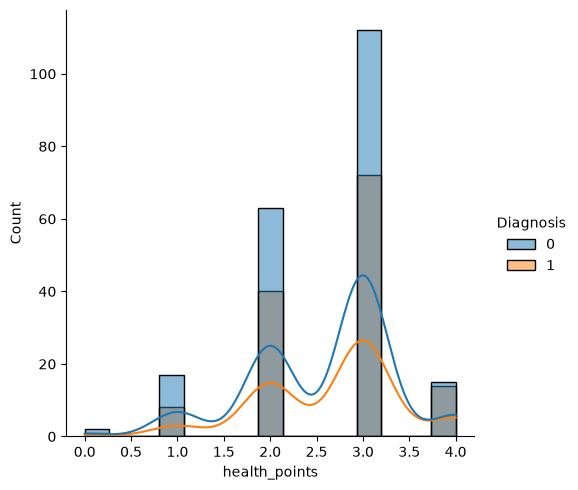

In [16]:
sns.displot(data=df_s, x="health_points", kde=True, hue="Diagnosis")
plt.show()

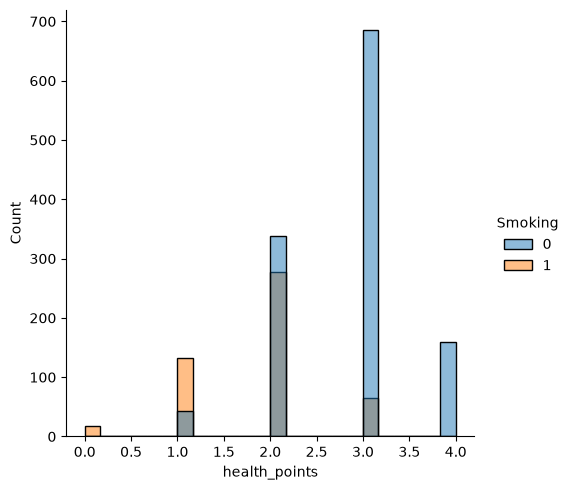

In [22]:
sns.displot(data=df, x="health_points", hue="Smoking")
plt.show()

it's a bit shady comparing this way. I think it's a better idea to verify only those who has the disease

In [30]:
df_has = df_s.loc[df_s["Diagnosis"] == 1]
df_hasnt = df_s.loc[df_s["Diagnosis"] == 0]

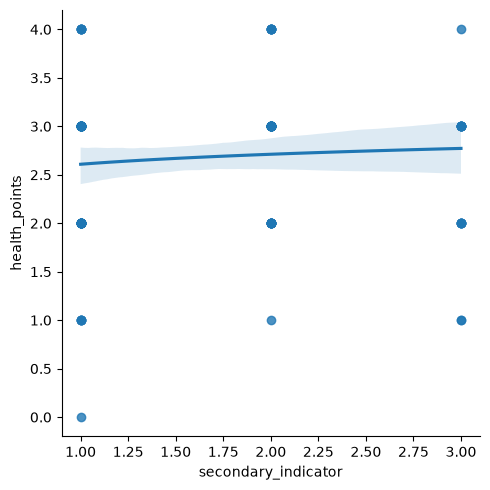

In [31]:
sns.lmplot(data=df_has, x="secondary_indicator", y="health_points", logx=True)
plt.show()

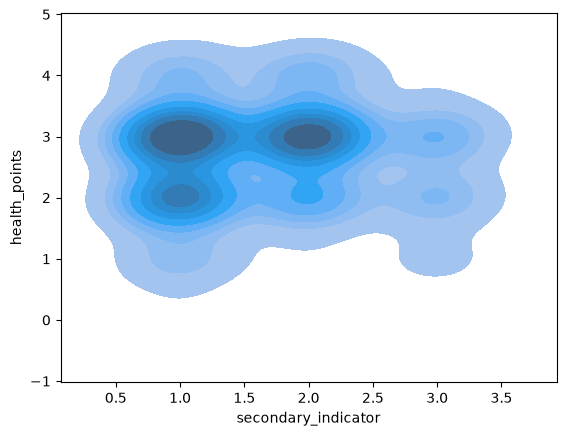

In [32]:
sns.kdeplot(data=df_has,x="secondary_indicator", y="health_points", fill=True)
plt.show()

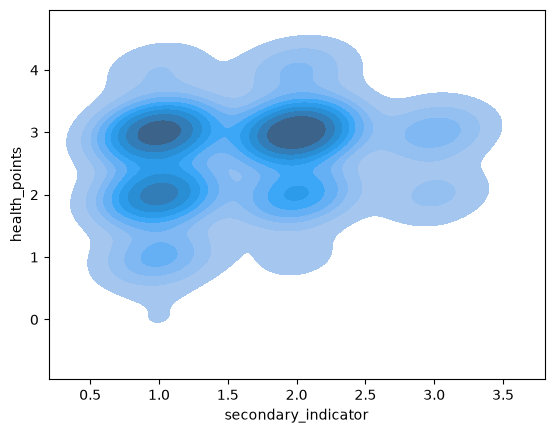

In [33]:
sns.kdeplot(data=df_hasnt,x="secondary_indicator", y="health_points", fill=True)
plt.show()

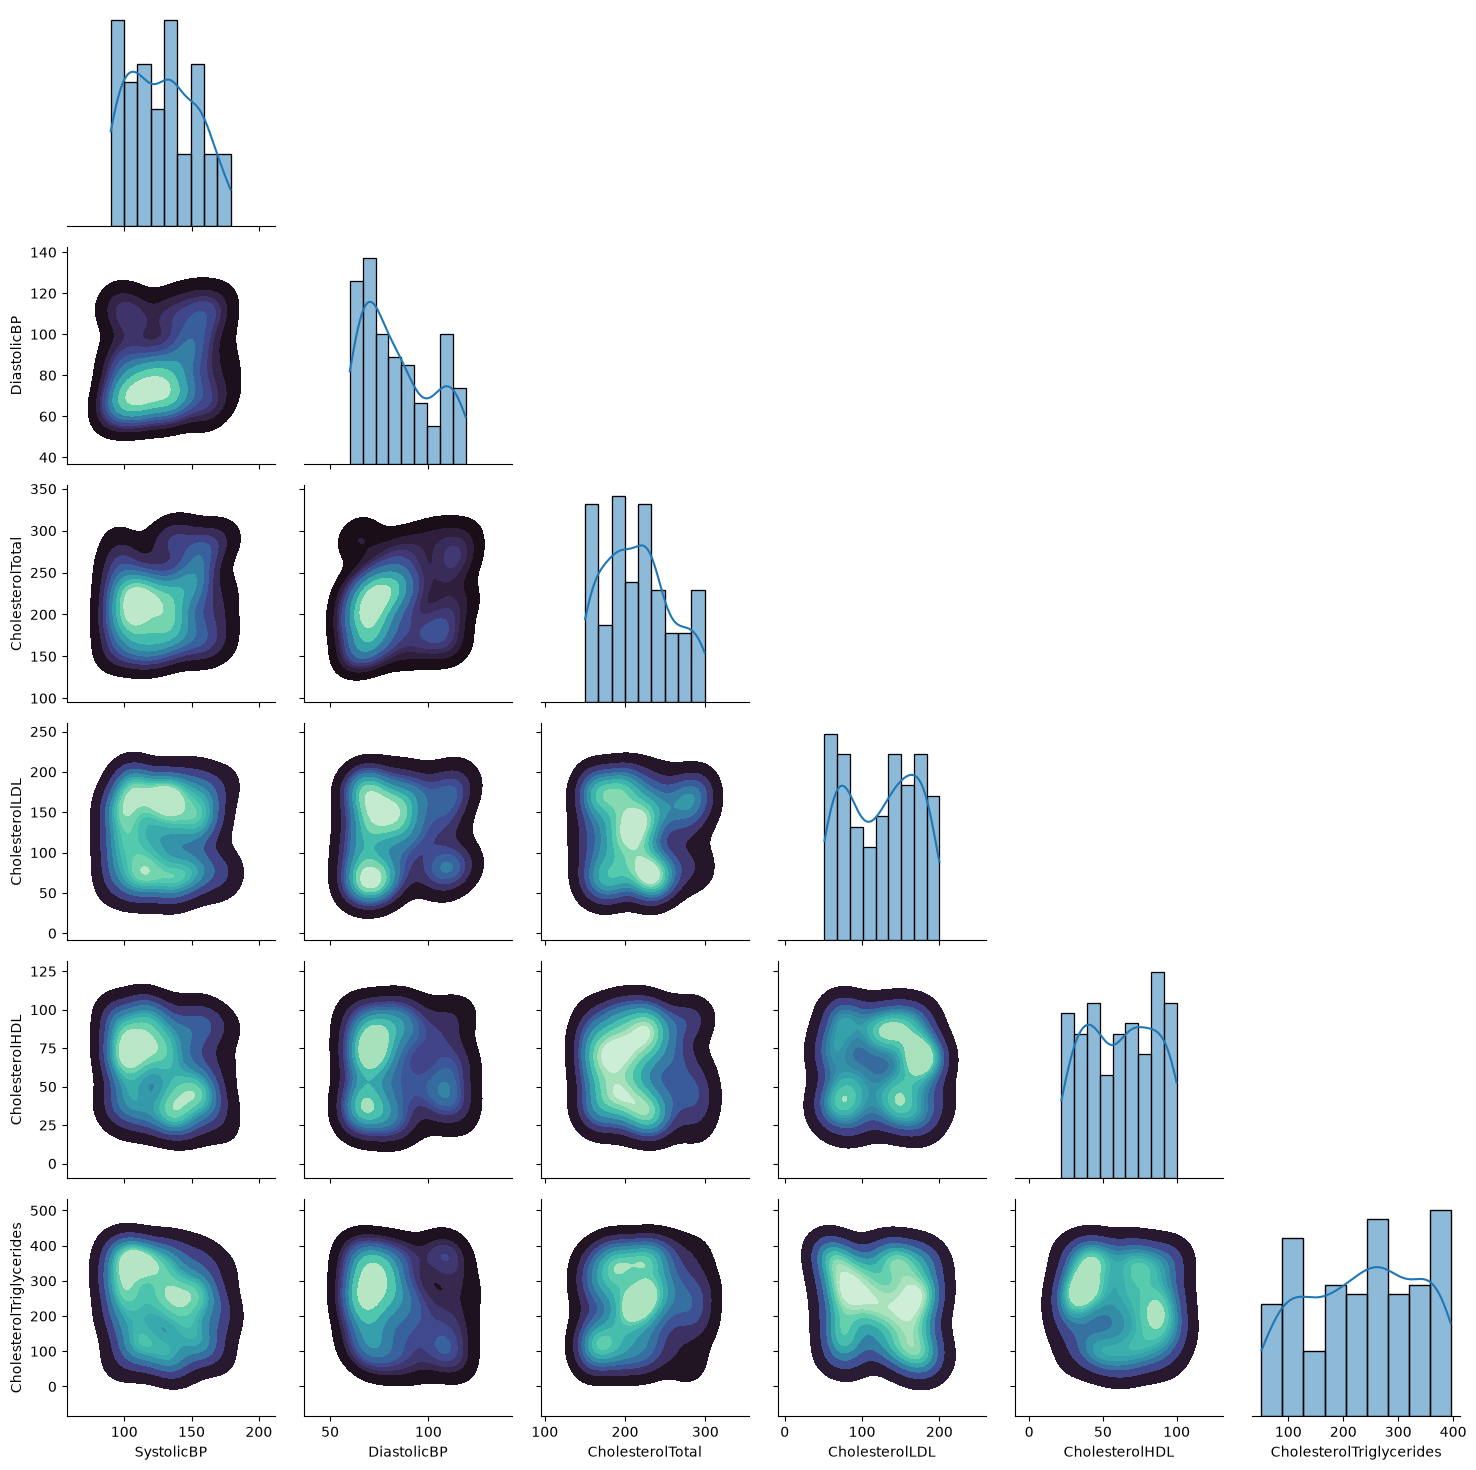

In [45]:
g = sns.PairGrid(df_has[["SystolicBP", "DiastolicBP", "CholesterolTotal", "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides"]], diag_sharey=False, corner=True)
g.map_lower(sns.kdeplot, fill=True, cmap="mako")
g.map_diag(sns.histplot, kde=True)
plt.show()

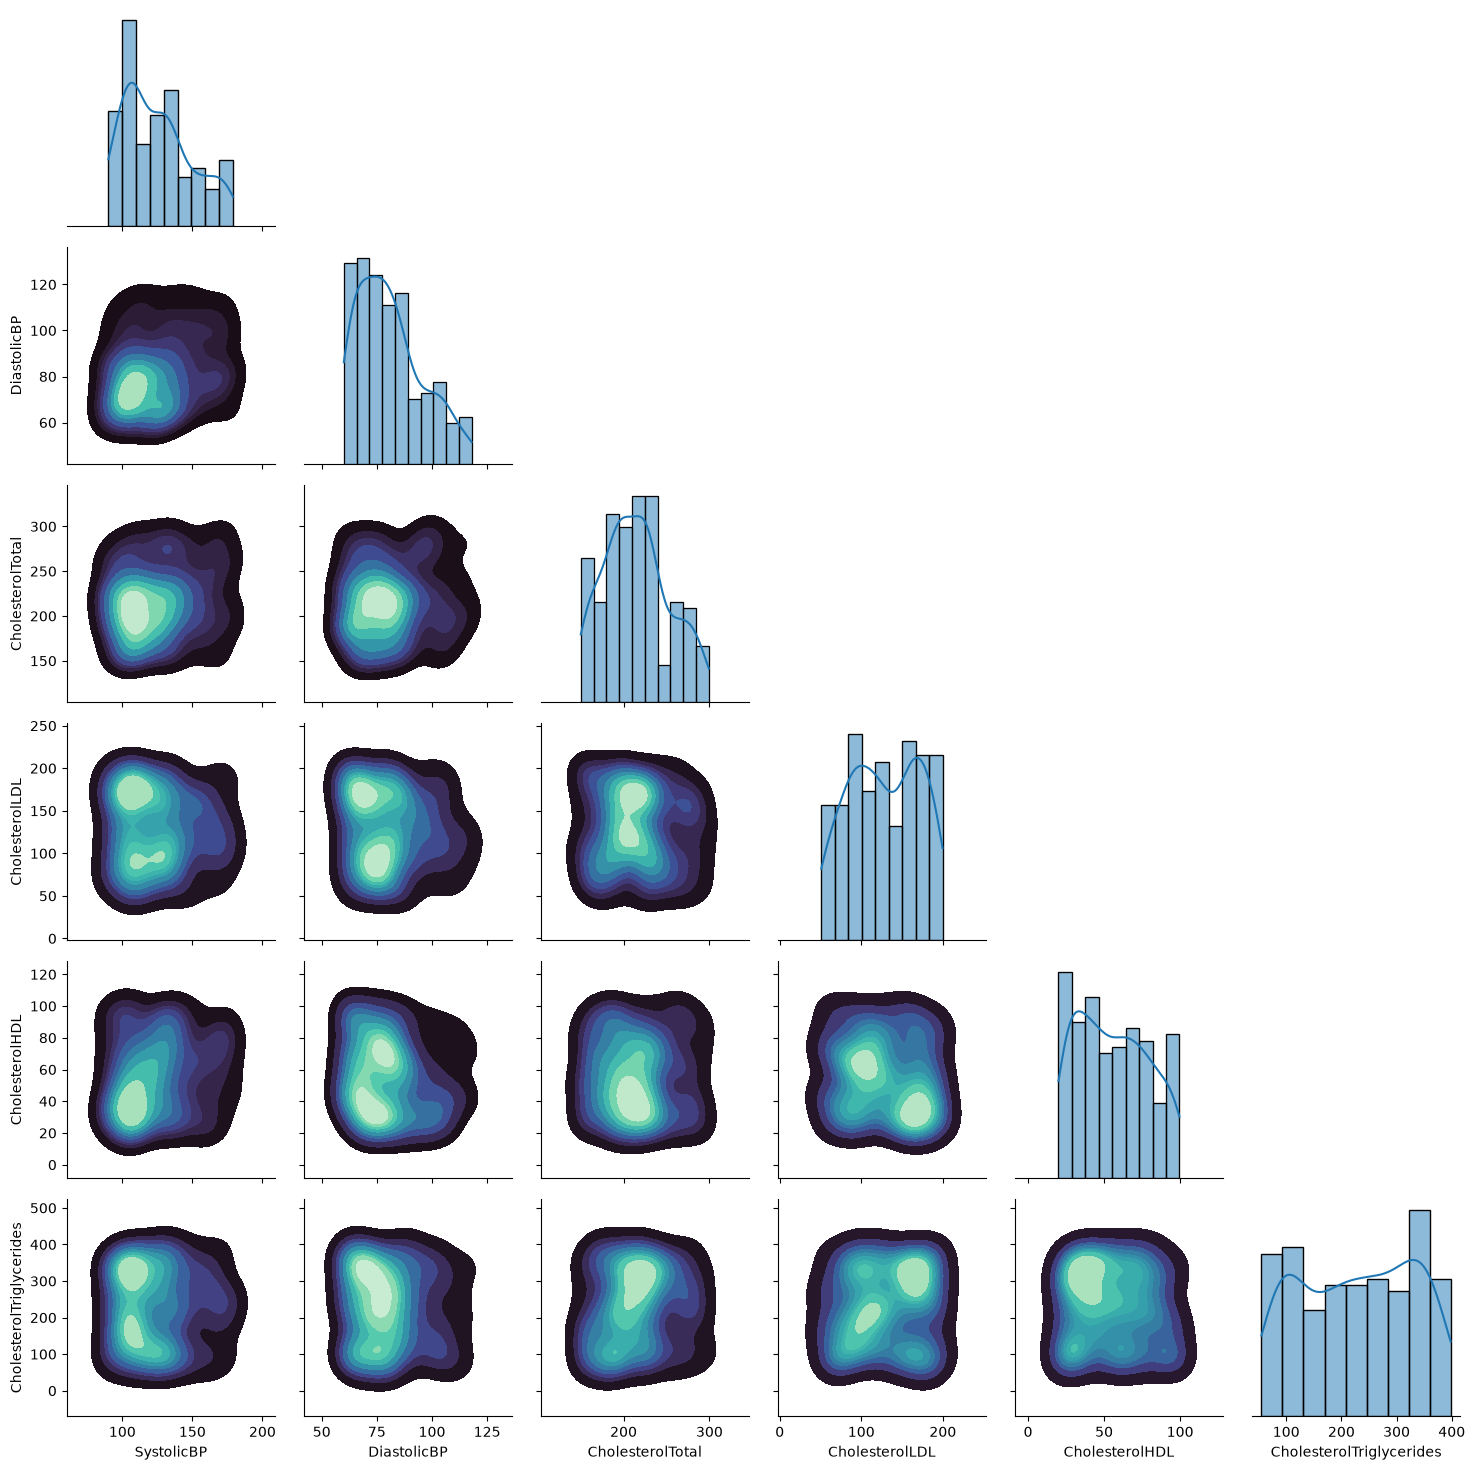

In [47]:
g = sns.PairGrid(df_hasnt[["SystolicBP", "DiastolicBP", "CholesterolTotal", "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides"]], diag_sharey=False, corner=True)
g.map_lower(sns.kdeplot, fill=True, cmap="mako")
g.map_diag(sns.histplot, kde=True)
plt.show()

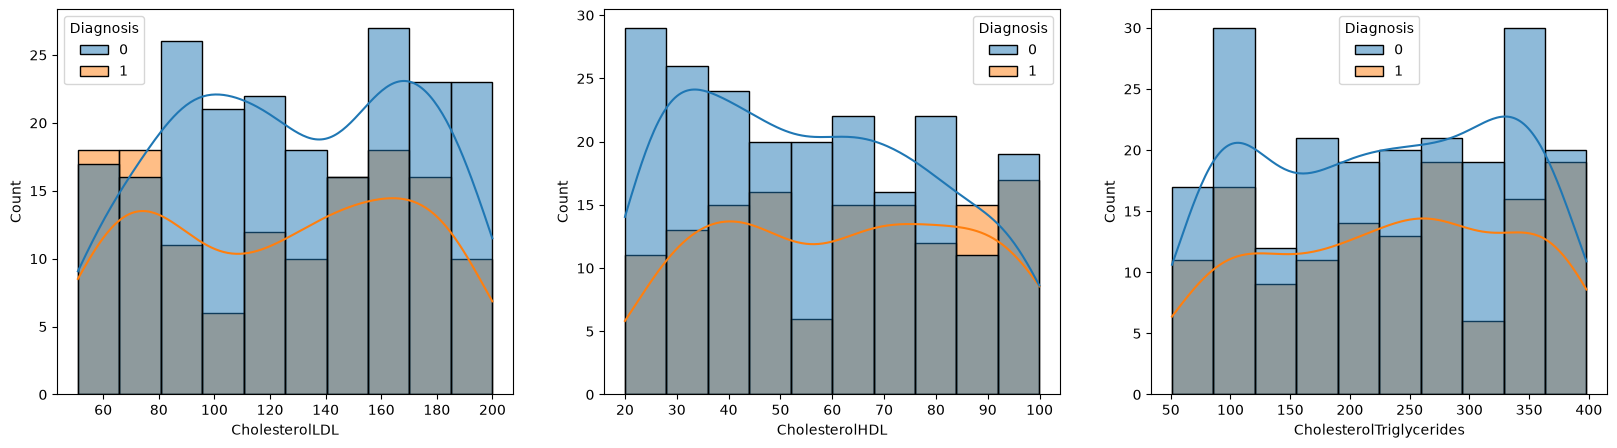

In [56]:
fig,ax = plt.subplots(1,3,figsize=(20,5))

sns.histplot(data=df_s, x="CholesterolLDL", hue="Diagnosis",ax=ax[0], kde=True)
sns.histplot(data=df_s, x="CholesterolHDL", hue="Diagnosis",ax=ax[1], kde=True)
sns.histplot(data=df_s, x="CholesterolTriglycerides", hue="Diagnosis",ax=ax[2], kde=True)
plt.show()

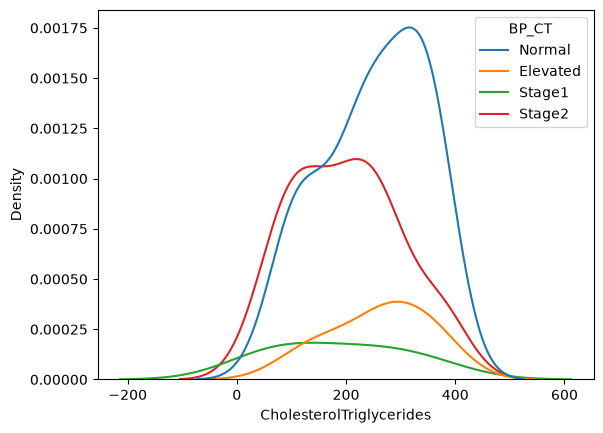

In [63]:
sns.kdeplot(data=df_has, x="CholesterolTriglycerides", hue="BP_CT")
plt.show()

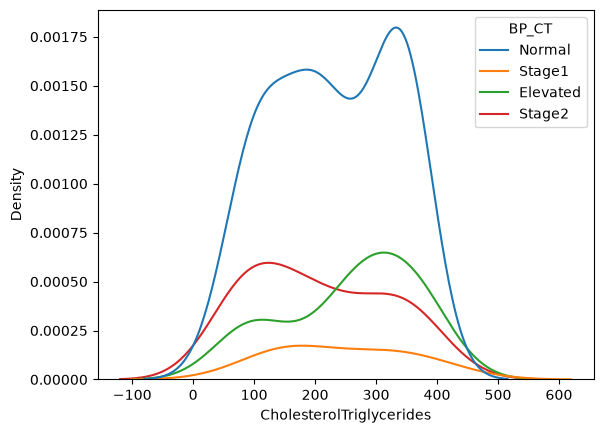

In [64]:
sns.kdeplot(data=df_hasnt, x="CholesterolTriglycerides", hue="BP_CT")
plt.show()

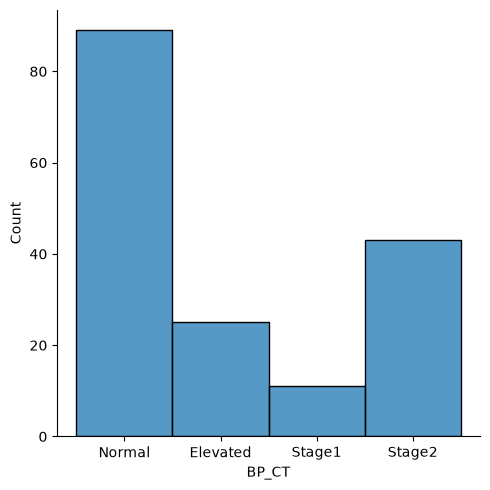

In [65]:
sns.displot(data=df_s, x="BP_CT")
plt.show()

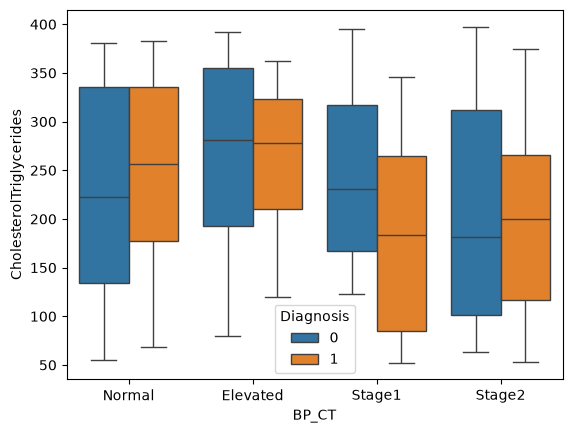

In [66]:
sns.boxplot(data=df_s, x="BP_CT", y="CholesterolTriglycerides", hue="Diagnosis")
plt.show()

It seems like, for those with normal cholesterol, the triglycerides affects the diagnosis, since the median for positive cases is higher than usual

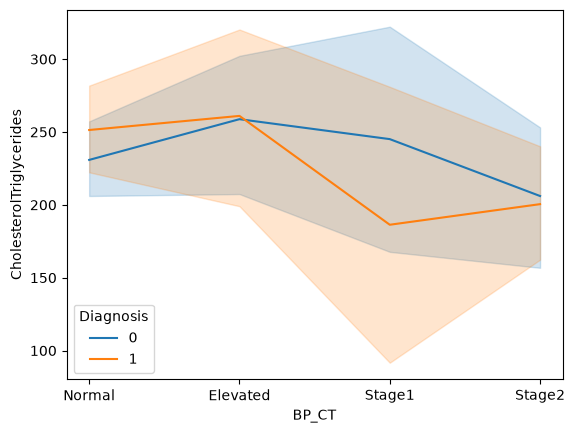

In [71]:
sns.lineplot(data=df_s, x="BP_CT", y="CholesterolTriglycerides", hue="Diagnosis")
plt.show()

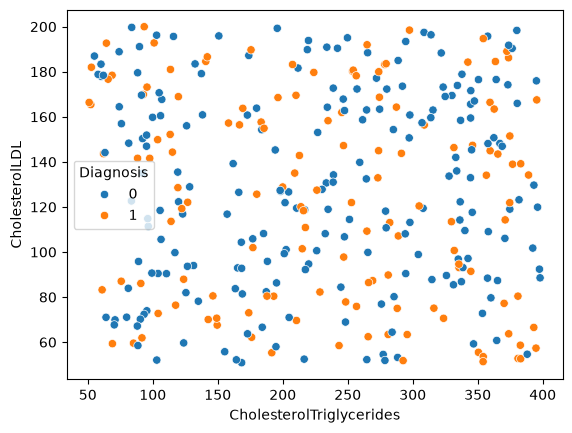

In [78]:
sns.scatterplot(data=df_s, x="CholesterolTriglycerides", y="CholesterolLDL", hue="Diagnosis")
plt.show()

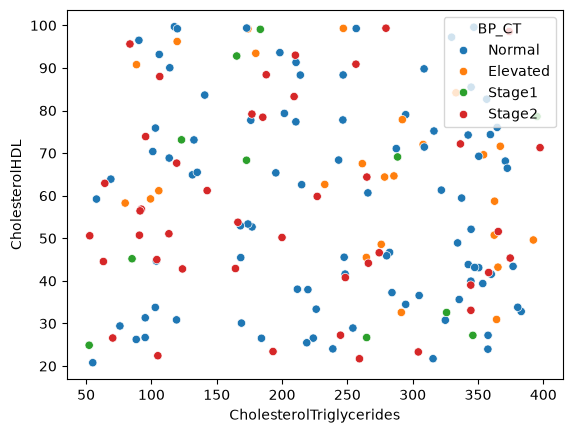

In [80]:
sns.scatterplot(data=df_s, x="CholesterolTriglycerides", y="CholesterolHDL", hue="BP_CT")
plt.show()

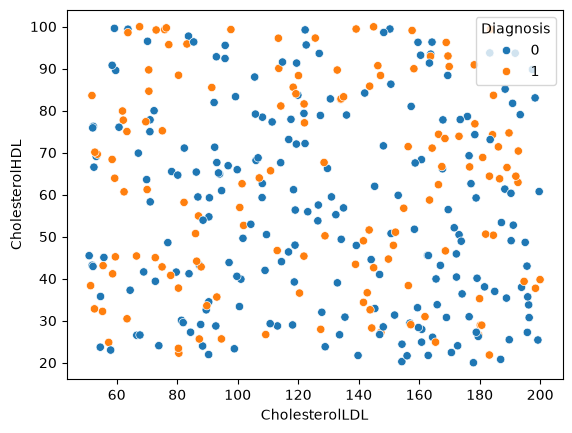

In [82]:
sns.scatterplot(data=df_s, x="CholesterolLDL", y="CholesterolHDL", hue="Diagnosis")
plt.show()

[![cholesterol levels](./assets/cholesterol.jpg)](https://my.clevelandclinic.org/health/articles/11920-cholesterol-numbers-what-do-they-mean)

In [96]:
print("Min age: ", int(df.Age.min()))

Min age:  60


In [134]:
# https://www.cdc.gov/cholesterol/about/ldl-and-hdl-cholesterol-and-triglycerides.html
# https://my.clevelandclinic.org/health/articles/11920-cholesterol-numbers-what-do-they-mean

df_s["CH_LEVEL"] = "Risk"
df_s.loc[(df_s["cholesterol"] < 200) & (((df_s["CholesterolHDL"] >= 40)&(df_s["Gender"] == 0)) | ((df_s["CholesterolHDL"] >= 50)&(df_s["Gender"] == 1))) & (df_s["CholesterolHDL"] <= 80) & (df_s["CholesterolLDL"] < 100),"CH_LEVEL"] = "Healthy"

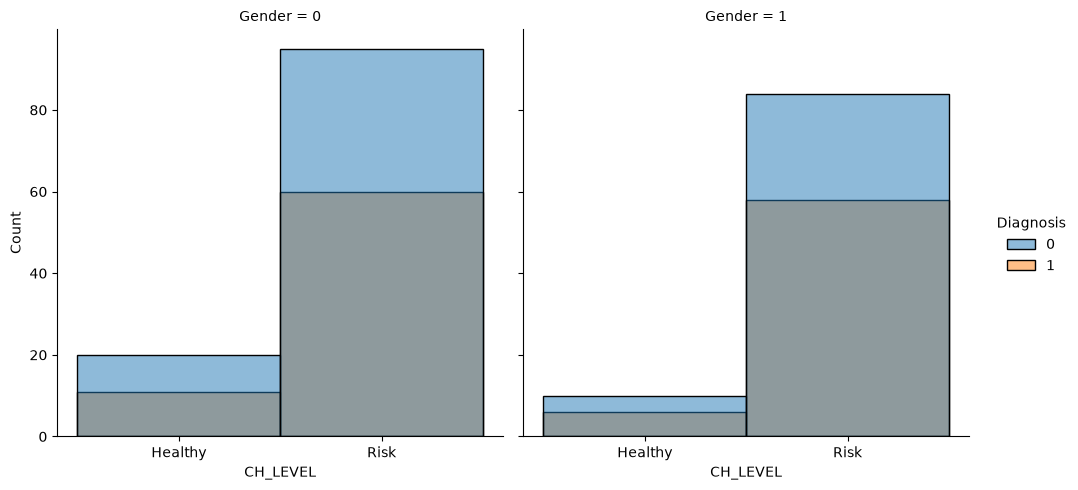

In [135]:
sns.displot(data=df_s, x="CH_LEVEL", hue="Diagnosis", col="Gender")
plt.show()

In [136]:
df_s["count_BP_CH"] = 0
count = df_s.groupby(by=["BP_CT", "CH_LEVEL", "Diagnosis"])
count.Diagnosis.count()

BP_CT     CH_LEVEL  Diagnosis
Elevated  Healthy   0             3
                    1             1
          Risk      0            15
                    1             6
Normal    Healthy   0             8
                    1             6
          Risk      0            48
                    1            27
Stage1    Healthy   0             1
          Risk      0             5
                    1             5
Stage2    Healthy   0             1
                    1             3
          Risk      0            19
                    1            20
Name: Diagnosis, dtype: int64

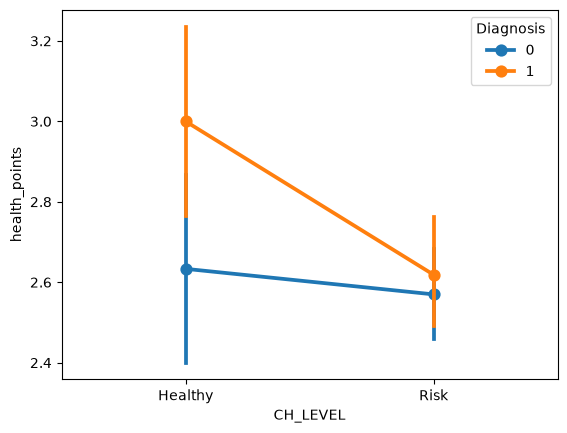

In [137]:
sns.pointplot(data=df_s, y="health_points", x="CH_LEVEL", hue="Diagnosis")
plt.show()

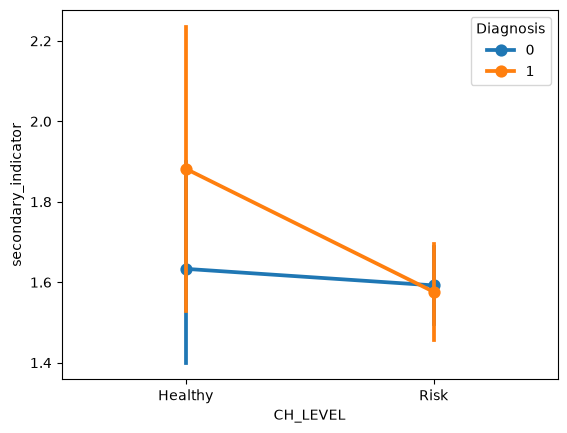

In [138]:
sns.pointplot(data=df_s, y="secondary_indicator", x="CH_LEVEL", hue="Diagnosis")
plt.show()

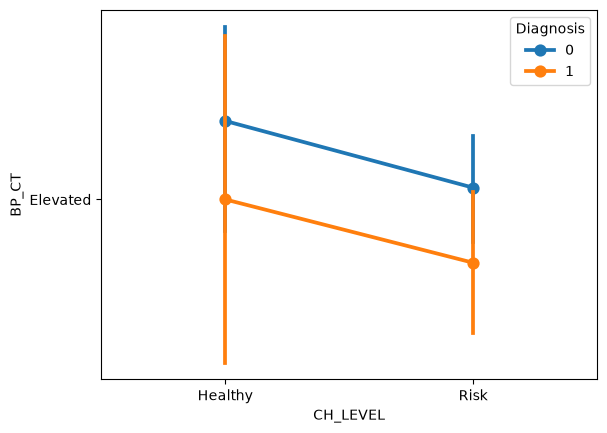

In [139]:
sns.pointplot(data=df_s, y="BP_CT", x="CH_LEVEL", hue="Diagnosis")
plt.show()

In [140]:
df_s["CH_LEVEL"].value_counts()

CH_LEVEL
Risk       297
Healthy     47
Name: count, dtype: int64

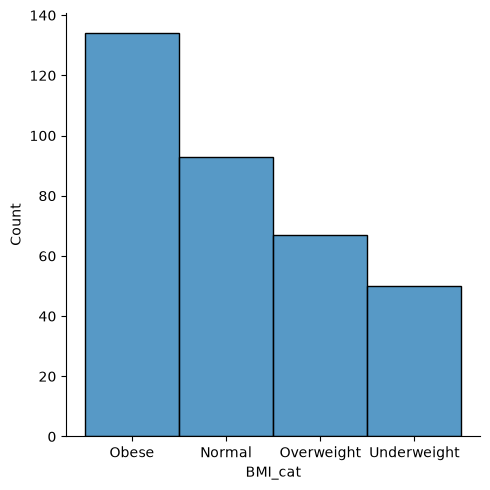

In [141]:
sns.displot(data=df_s, x="BMI_cat")
plt.show()

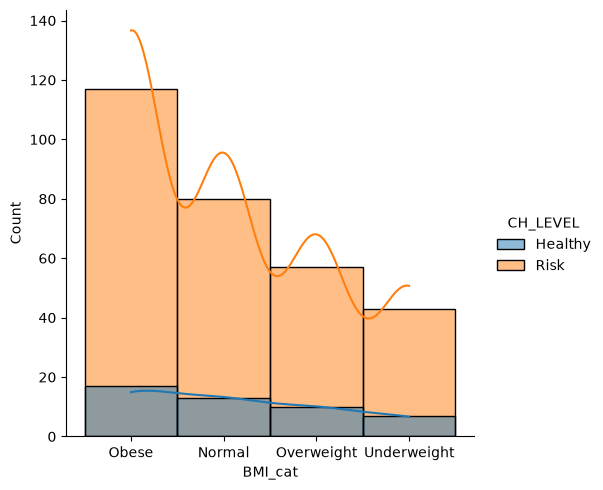

In [142]:
sns.displot(data=df_s, x="BMI_cat", hue="CH_LEVEL", kde=True)
plt.show()

In [143]:
df_s["BMI_cat"].value_counts()

BMI_cat
Obese          134
Normal          93
Overweight      67
Underweight     50
Name: count, dtype: int64

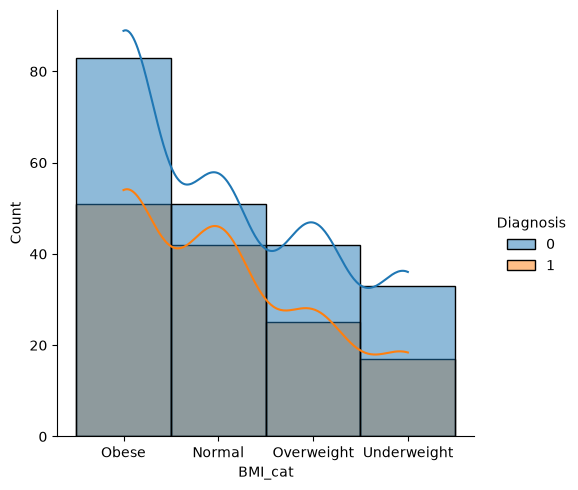

In [127]:
sns.displot(data=df_s, x="BMI_cat", hue="Diagnosis", kde=True)
plt.show()

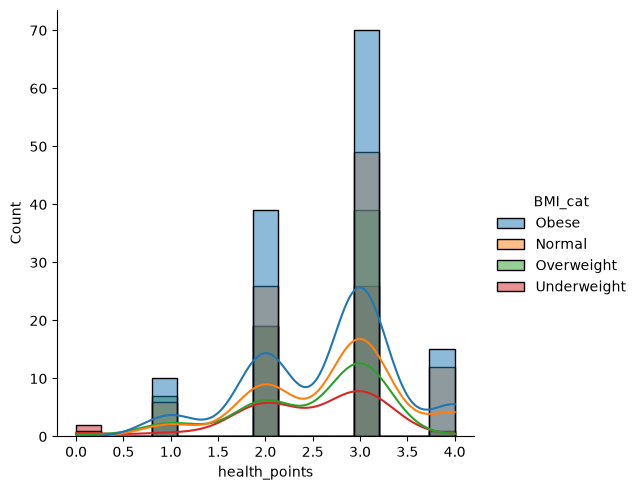

In [128]:
sns.displot(data=df_s, x="health_points", hue="BMI_cat", kde=True)
plt.show()

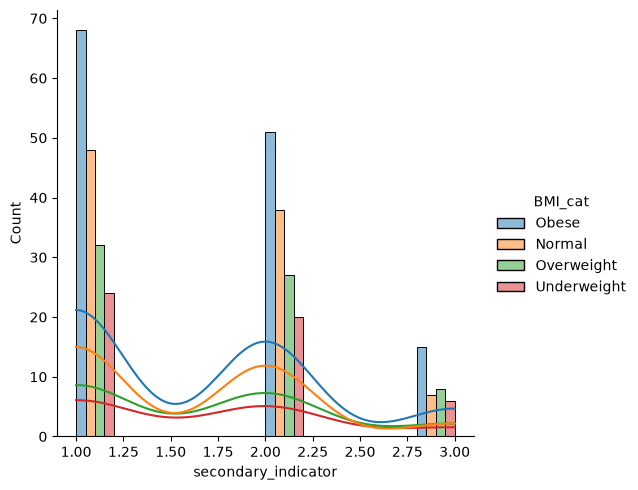

In [130]:
sns.displot(data=df_s, x="secondary_indicator", hue="BMI_cat", kde=True, multiple="dodge")
plt.show()

<Axes: xlabel='secondary_indicator', ylabel='BMI'>

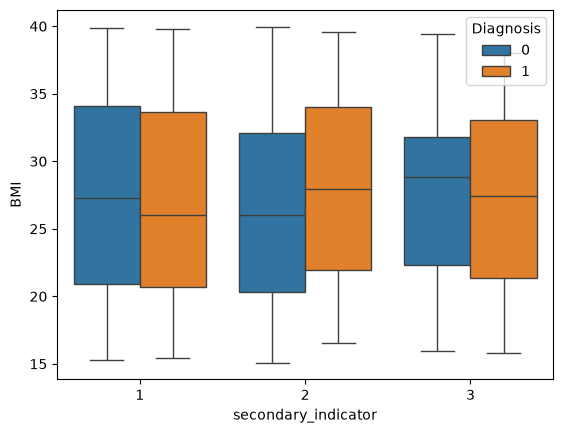

In [133]:
sns.boxplot(data=df_s, y="BMI", x="secondary_indicator", hue="Diagnosis")

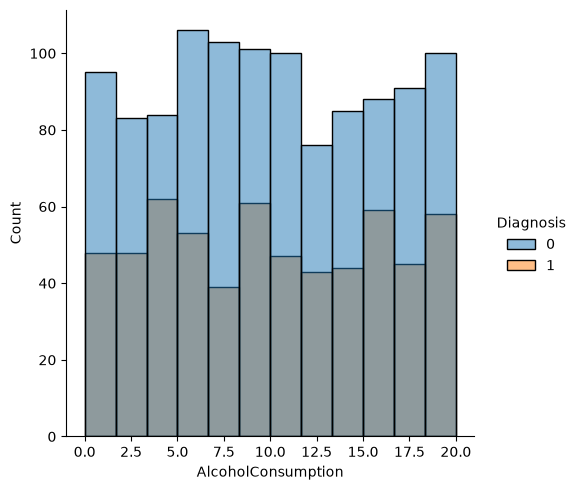

In [146]:
sns.displot(data=df, x="AlcoholConsumption", hue="Diagnosis")
plt.show()

It all became too messy to continue this way. I think we lost the knowledge of what our data actually is.

I suggest start it again in a fresh notebook `analysis3.ipynb`